In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
turbines = pd.read_parquet("/Users/zsquirrel/Downloads/WindChasersData/alta10_turbine_data_grouped.parquet")

In [3]:
turbines.head()

turbine                  wtg150                                    \
variable            air_density blade_position_2 blade_position_3   
utc_time                                                            
2026-01-01 08:00:00    1.092081        -1.056245        -0.643520   
2026-01-01 08:10:00    0.800856        -1.077751        -0.680390   
2026-01-01 08:20:00    1.089478        -0.445800        -0.039797   
2026-01-01 08:30:00    0.800936        -1.205972        -0.786801   
2026-01-01 08:40:00    1.090836        -1.205672        -0.786363   

turbine                                                                  \
variable            blade_setpoint_position_1 blade_setpoint_position_2   
utc_time                                                                  
2026-01-01 08:00:00                  2.307242                 -0.892182   
2026-01-01 08:10:00                  2.354385                 -0.845038   
2026-01-01 08:20:00                  2.813232                 -0.386191   
2026-01-01 08:30:00                       NaN                       NaN   
2026-01-01 08:40:00                       NaN                       NaN   

turbine                                                                        \
variable            blade_setpoint_position_3 nacelle_position real_power_a_c   
utc_time                                                                        
2026-01-01 08:00:00                 -0.471435       118.785714      672.60510   
2026-01-01 08:10:00                 -0.424893       117.066667      541.30096   
2026-01-01 08:20:00                  0.032674       118.812500      237.94884   
2026-01-01 08:30:00                       NaN              NaN      503.22354   
2026-01-01 08:40:00                       NaN       130.000000      444.42767   

turbine                                                   ...  \
variable            real_power_a_c_2 temperature_ambient  ...   
utc_time                                                  ...   
2026-01-01 08:00:00       670.286714            8.299405  ...   
2026-01-01 08:10:00       542.747853            8.573889  ...   
2026-01-01 08:20:00       239.185173            8.972823  ...   
2026-01-01 08:30:00       504.556470            8.531316  ...   
2026-01-01 08:40:00       444.157211            8.621079  ...   

turbine                       wtg197                                  \
variable            nacelle_position real_power_a_c real_power_a_c_2   
utc_time                                                               
2026-01-01 08:00:00        62.500000      1232.1998      1229.936331   
2026-01-01 08:10:00        59.000000       990.2687       990.641605   
2026-01-01 08:20:00        58.666667      1074.2076      1074.568828   
2026-01-01 08:30:00        67.333333      1108.8040      1108.957917   
2026-01-01 08:40:00        67.100000      1124.4481      1123.277779   

turbine                                                             \
variable            temperature_ambient temperature_ambient_merged   
utc_time                                                             
2026-01-01 08:00:00            6.258348                   6.258348   
2026-01-01 08:10:00            6.331188                   6.331188   
2026-01-01 08:20:00            6.456590                   6.456590   
2026-01-01 08:30:00            6.545990                   6.545990   
2026-01-01 08:40:00            6.563307                   6.563307   

turbine                                                                       \
variable            theoretical_power wind_direction wind_direction_relative   
utc_time                                                                       
2026-01-01 08:00:00         1418.4381      54.739130               -6.454545   
2026-01-01 08:10:00          817.2081      52.763514               -5.510949   
2026-01-01 08:20:00         1234.4576      53.654930               -4.808824   
2026-01-01 08:30:00          843.8777      60.771812      

In [5]:
import seaborn as sns

# Extract raw wind speeds from every turbine
wind = turbines.xs("wind_speed", axis=1, level="variable").copy()

# Standardize turbine names
wind.columns = wind.columns.str.lower()

# Convert values to numeric
wind = wind.apply(pd.to_numeric, errors="coerce")

# Exclude turbines with documented generator failures
wind = wind.drop(columns=["wtg169", "wtg183"], errors="ignore")

# Flag clearly suspicious readings (preliminary threshold)
wind = wind.where((wind >= 0) & (wind <= 40))

print("Dataset shape:", wind.shape)
print(wind.head())

Dataset shape: (4464, 45)
turbine                wtg150    wtg151    wtg152    wtg153    wtg154  \
utc_time                                                                
2026-01-01 08:00:00  6.906036  5.730449  5.862610  5.969328  4.760764   
2026-01-01 08:10:00  6.609679  5.477940  5.610396  5.871838  4.329586   
2026-01-01 08:20:00  5.210308  4.240477  5.174487  5.721522  4.978105   
2026-01-01 08:30:00  6.510418  5.377338  5.057247  5.432190  4.729747   
2026-01-01 08:40:00  6.093416  5.174675  5.664870  6.017239  4.808846   

turbine                wtg155    wtg156    wtg157    wtg158    wtg159  ...  \
utc_time                                                               ...   
2026-01-01 08:00:00  5.551334  5.196425  5.521146  5.178299  4.061986  ...   
2026-01-01 08:10:00  5.762332  4.829579  5.781654  4.966896  5.086618  ...   
2026-01-01 08:20:00  6.281947  5.976226  6.209143  5.305197  5.494353  ...   
2026-01-01 08:30:00  5.460868  4.748529  5.125973  4.821038  5.256970  .

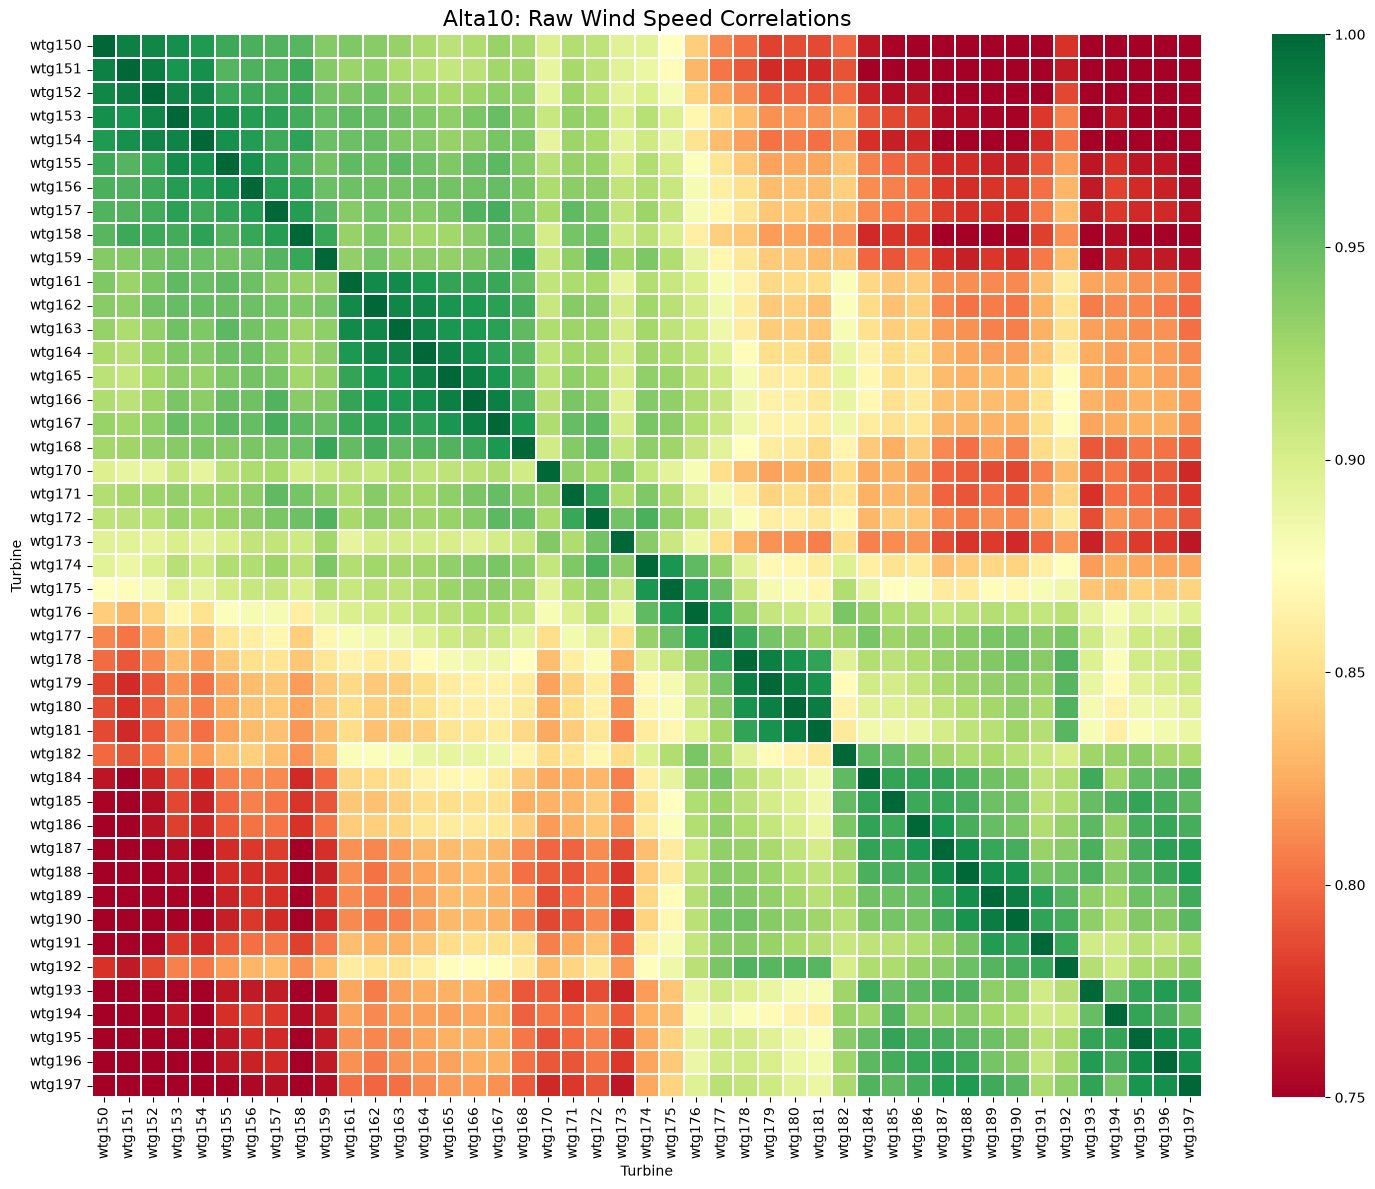

In [11]:
# Correlation between all turbines for similar wind speed patterns
corr_matrix = wind.corr(min_periods=1000)

# Display correlation heatmap
plt.figure(figsize=(15, 12))

sns.heatmap(
    corr_matrix,
    cmap="RdYlGn",       # Red → Yellow → Green
    vmin=0.75,
    vmax=1.0,
    center=0.875,
    linewidths=0.15
)

plt.title("Alta10: Raw Wind Speed Correlations", fontsize=16)
plt.xlabel("Turbine")
plt.ylabel("Turbine")
plt.tight_layout()
plt.show()

In [12]:
target = "wtg150"

top_partners = (
    corr_matrix[target]
    .drop(target)
    .sort_values(ascending=False)
    .head(5)
)

print(top_partners)

turbine
wtg151    0.986828
wtg152    0.983558
wtg153    0.978941
wtg154    0.973010
wtg155    0.963693
Name: wtg150, dtype: float64


In [13]:
results = []

for turbine in corr_matrix.columns:
    top_3 = (
        corr_matrix[turbine]
        .drop(turbine)
        .dropna()
        .nlargest(3)
    )

    results.append({
        "Turbine": turbine,
        "Partner 1": top_3.index[0],
        "Correlation 1": round(top_3.iloc[0], 4),
        "Partner 2": top_3.index[1],
        "Correlation 2": round(top_3.iloc[1], 4),
        "Partner 3": top_3.index[2],
        "Correlation 3": round(top_3.iloc[2], 4)
    })

partners_df = pd.DataFrame(results)

display(partners_df)

,Turbine,Partner 1,Correlation 1,Partner 2,Correlation 2,Partner 3,Correlation 3
0,wtg150,wtg151,0.9868,wtg152,0.9836,wtg153,0.9789
1,wtg151,wtg152,0.9889,wtg150,0.9868,wtg154,0.9778
2,wtg152,wtg151,0.9889,wtg154,0.9847,wtg153,0.9844
3,wtg153,wtg154,0.9845,wtg152,0.9844,wtg155,0.9809
4,wtg154,wtg152,0.9847,wtg153,0.9845,wtg155,0.9779
5,wtg155,wtg153,0.9809,wtg154,0.9779,wtg156,0.9777
6,wtg156,wtg155,0.9777,wtg154,0.9726,wtg153,0.9716
7,wtg157,wtg156,0.9710,wtg158,0.9709,wtg153,0.9689
8,wtg158,wtg157,0.9709,wtg154,0.9679,wtg159,0.9655
9,wtg159,wtg168,0.9655,wtg158,0.9655,wtg172,0.9567


In [14]:
# Evaluate consistency of each turbine's strongest partner
pairs = {
    tuple(sorted([row["Turbine"], row["Partner 1"]]))
    for _, row in partners_df.iterrows()
}

results = []

for a, b in sorted(pairs):
    paired = wind[[a, b]].dropna()
    difference = paired[a] - paired[b]

    results.append({
        "Turbine A": a,
        "Turbine B": b,
        "Correlation": corr_matrix.loc[a, b],
        "Mean Difference": difference.mean(),
        "SD Difference": difference.std(),
        "Observations": len(paired)
    })

difference_df = pd.DataFrame(results)

difference_df = difference_df.sort_values("SD Difference")

display(difference_df.head(15).round(4))

,Turbine A,Turbine B,Correlation,Mean Difference,SD Difference,Observations
14,wtg166,wtg167,0.9883,-0.1797,0.5376,4458
29,wtg189,wtg190,0.9885,-0.0656,0.5430,4458
13,wtg165,wtg166,0.9875,-0.1188,0.5489,4458
12,wtg164,wtg165,0.9857,0.0625,0.5846,4458
1,wtg151,wtg152,0.9889,-0.1361,0.5910,4458
23,wtg180,wtg181,0.9888,-0.2426,0.5957,4446
11,wtg163,wtg164,0.9848,0.3662,0.6095,4458
22,wtg179,wtg180,0.9881,0.1292,0.6130,4446
34,wtg195,wtg196,0.9809,-0.4337,0.6135,4458
3,wtg153,wtg154,0.9845,0.9976,0.6201,4340


In [15]:
print("Total timestamps:", len(wind))
print("Start date:", wind.index.min())
print("End date:", wind.index.max())
print("Number of turbines:", wind.shape[1])

Total timestamps: 4464
Start date: 2026-01-01 08:00:00
End date: 2026-02-01 07:50:00
Number of turbines: 45


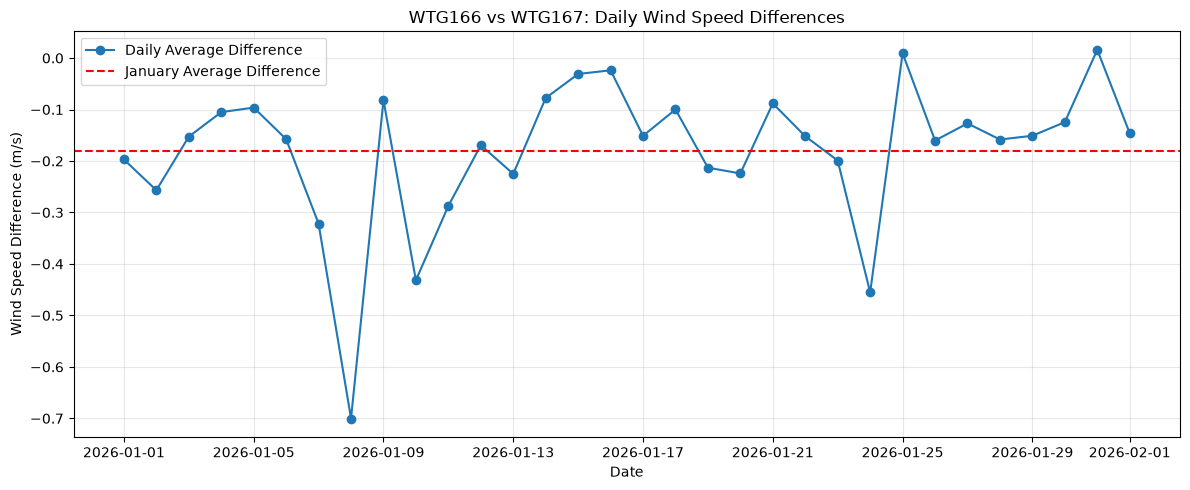

In [16]:
# Examine daily wind-speed differences for WTG166 and WTG167

difference = wind["wtg166"] - wind["wtg167"]

daily_difference = difference.resample("D").mean()

plt.figure(figsize=(12, 5))

plt.plot(daily_difference.index, daily_difference,
         marker="o", label="Daily Average Difference")

plt.axhline(
    difference.mean(),
    color="red",
    linestyle="--",
    label="January Average Difference"
)

plt.title("WTG166 vs WTG167: Daily Wind Speed Differences")
plt.xlabel("Date")
plt.ylabel("Wind Speed Difference (m/s)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [17]:
difference = (wind["wtg166"] - wind["wtg167"]).dropna()

daily_stats = difference.resample("D").agg(
    ["mean", "median", "std", "count"]
)

display(
    daily_stats.loc[
        ["2026-01-08", "2026-01-24"]
    ].round(3)
)

,mean,median,std,count
utc_time,,,,
2026-01-08,-0.700,-0.781,1.325,143
2026-01-24,-0.455,-0.265,1.432,144


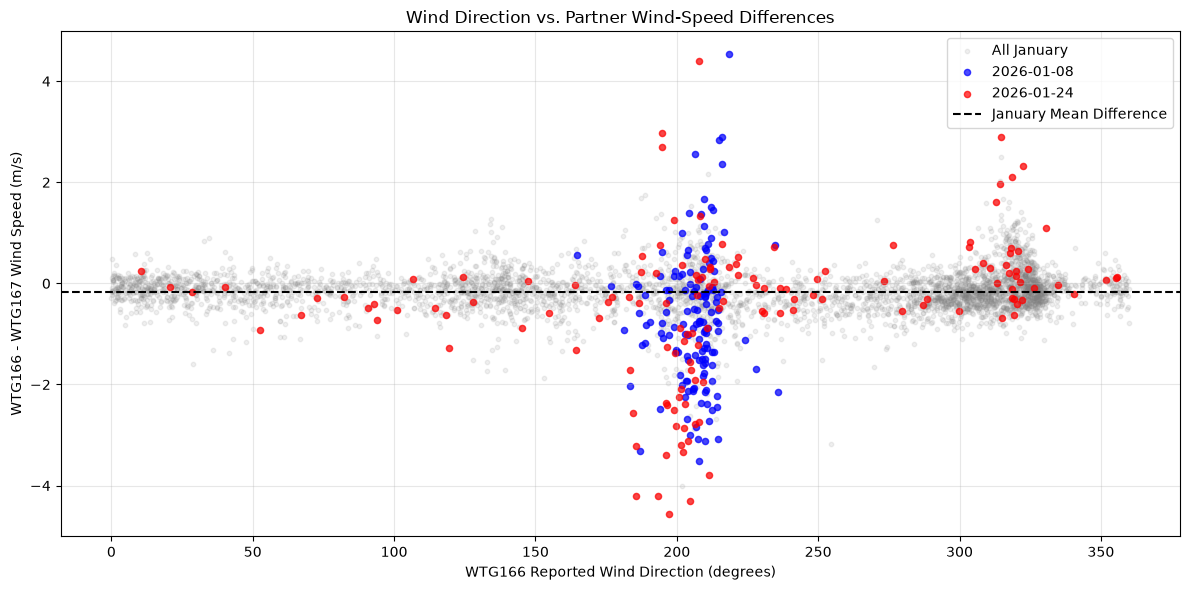

In [19]:
# Compare partner differences with wind direction
direction = turbines.xs(
    "wind_direction", axis=1, level="variable"
)["wtg166"]

check = pd.DataFrame({
    "difference": wind["wtg166"] - wind["wtg167"],
    "direction": direction
}).dropna()

check["direction"] = check["direction"] % 360

plt.figure(figsize=(12, 6))

# All January observations
plt.scatter(
    check["direction"],
    check["difference"],
    alpha=0.12,
    s=10,
    color="gray",
    label="All January"
)

# Highlight the two unusual days
for date, color in [
    ("2026-01-08", "blue"),
    ("2026-01-24", "red")
]:
    subset = check.loc[date]
    plt.scatter(
        subset["direction"],
        subset["difference"],
        s=20,
        alpha=0.7,
        color=color,
        label=date
    )

plt.axhline(
    -0.1797,
    color="black",
    linestyle="--",
    label="January Mean Difference"
)

plt.xlabel("WTG166 Reported Wind Direction (degrees)")
plt.ylabel("WTG166 - WTG167 Wind Speed (m/s)")
plt.title("Wind Direction vs. Partner Wind-Speed Differences")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [20]:
# Compare wind-speed differences across 20-degree wind sectors

check["sector"] = pd.cut(
    check["direction"],
    bins=np.arange(0, 361, 20),
    right=False
)

sector_stats = (
    check.groupby("sector", observed=True)["difference"]
    .agg(
        Observations="count",
        Mean="mean",
        Median="median",
        SD="std"
    )
    .round(3)
)

display(sector_stats)

,Observations,Mean,Median,SD
sector,,,,
"[0, 20)",247,-0.089,-0.085,0.222
"[20, 40)",175,-0.129,-0.101,0.285
"[40, 60)",143,-0.179,-0.140,0.319
"[60, 80)",113,-0.172,-0.105,0.271
"[80, 100)",103,-0.170,-0.126,0.285
"[100, 120)",125,-0.184,-0.133,0.293
"[120, 140)",268,-0.099,-0.096,0.412
"[140, 160)",210,-0.205,-0.187,0.350
"[160, 180)",142,-0.159,-0.133,0.387
